# 🪐 Planet Hunters — starter notebook
**ML Challenge Hack4Hack 2026 · Round 1**

This notebook loads the data, plots a few stars, builds simple statistics for every star, trains a gradient-boosting model and writes a valid `submission.csv`.

It is a **baseline**: it ignores periods, dip shapes, centroids and flares, so it scores low. Beating it is your job. It runs in about 2 minutes on a laptop with 8 GB RAM.

Put this notebook in the same folder as the data files (or change `DATA` below).

In [21]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

DATA = '../data/raw'   # folder with the .npy and .csv files
train_flux = np.load(f'{DATA}/train_flux.npy', mmap_mode='r')        # (18000, 1315) electrons/s, NaN = gap
train_cen  = np.load(f'{DATA}/train_centroid.npy', mmap_mode='r')    # (18000, 2, 1315) millipixels
test_flux  = np.load(f'{DATA}/test_flux.npy', mmap_mode='r')
train = pd.read_csv(f'{DATA}/train_stars.csv')
test  = pd.read_csv(f'{DATA}/test_stars.csv')
test_cen  = np.load(f'{DATA}/test_centroid.npy', mmap_mode='r') 
cad   = pd.read_csv(f'{DATA}/train_cadences.csv')
t = cad.time_btjd.values
print(train_flux.shape, test_flux.shape)
train.label.value_counts()

(18000, 1315) (7000, 1315)


label
quiet_star           3624
starspots            2882
eclipsing_binary     2247
planet               2145
pulsating_star       1973
flare_star           1804
instrument_glitch    1721
background_binary    1604
Name: count, dtype: int64

## Look at the data
One star of each label: relative brightness (top) and centroid column offset (bottom). Orange ticks mark momentum dumps (`quality & 1`).

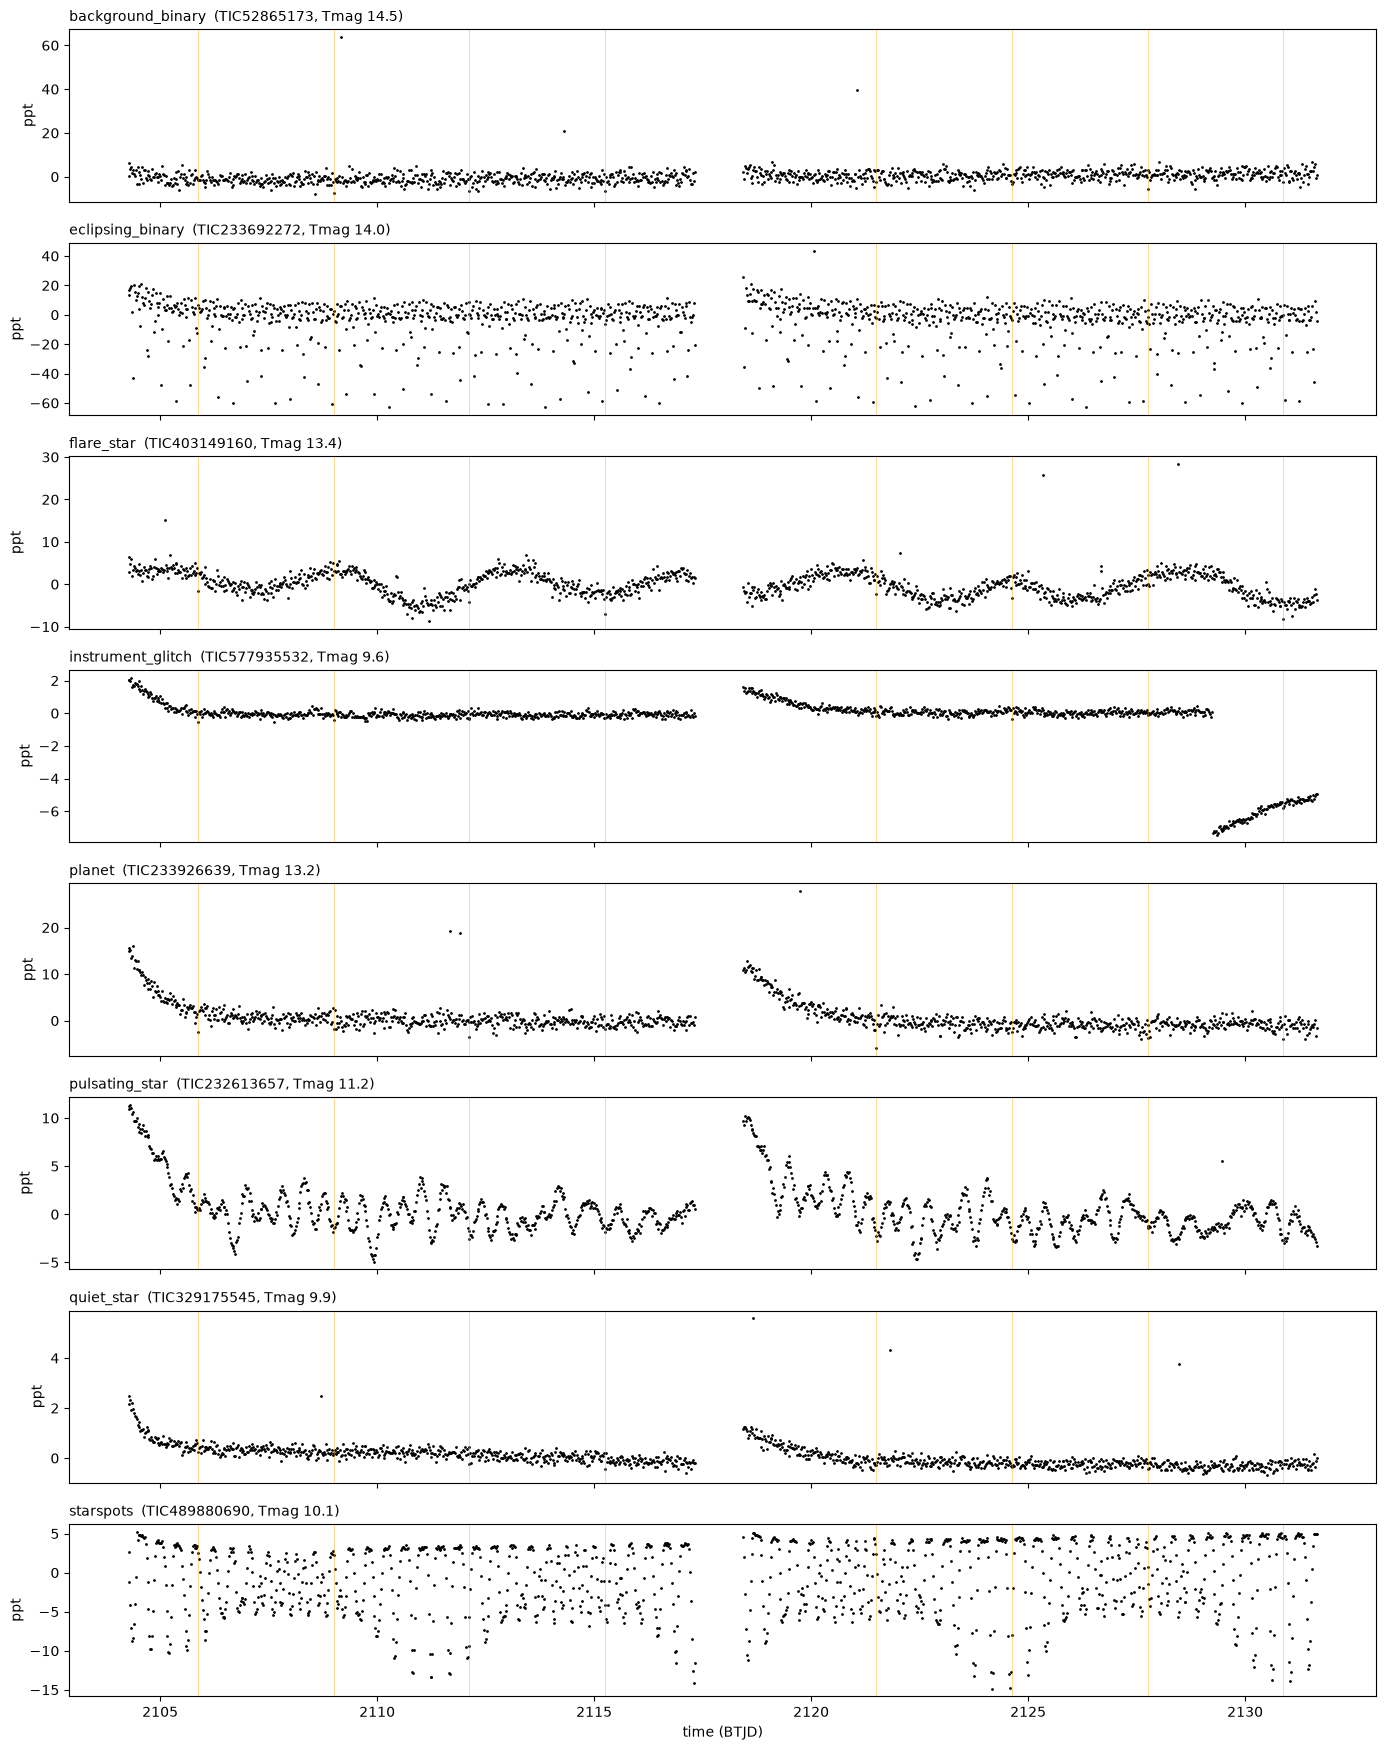

In [2]:
labels = sorted(train.label.unique())
fig, axes = plt.subplots(len(labels), 1, figsize=(14, 2.2 * len(labels)), sharex=True)
dumps = t[(cad.quality.values & 1) > 0]
for ax, lab in zip(axes, labels):
    i = train.index[train.label == lab][0]
    f = train_flux[i] / np.nanmedian(train_flux[i]) - 1
    ax.plot(t, f * 1e3, '.', ms=2, color='k')
    for d in dumps: ax.axvline(d, color='orange', lw=0.5, alpha=0.6)
    ax.set_ylabel('ppt'); ax.set_title(f'{lab}  ({train.id[i]}, Tmag {train.tmag[i]:.1f})', fontsize=10, loc='left')
axes[-1].set_xlabel('time (BTJD)'); plt.tight_layout(); plt.show()

## Simple features
Normalise each star by its median, then compute spread, extremes, skewness and percentiles. Add the star properties from the CSV.

In [3]:
def simple_features(flux, stars, batch=2000):
    out = []
    for s in range(0, len(flux), batch):
        f = np.asarray(flux[s:s + batch], np.float64)
        f = f / np.nanmedian(f, axis=1, keepdims=True) - 1
        out.append(pd.DataFrame({
            'std': np.nanstd(f, 1),
            'mad': np.nanmedian(np.abs(f - np.nanmedian(f, 1, keepdims=True)), 1),
            'min': np.nanmin(f, 1), 'max': np.nanmax(f, 1),
            'skew': stats.skew(f, 1, nan_policy='omit'), 'kurt': stats.kurtosis(f, 1, nan_policy='omit'),
            **{f'p{q}': np.nanpercentile(f, q, 1) for q in (1, 5, 25, 75, 95, 99)},
        }))
    X = pd.concat(out, ignore_index=True)
    return pd.concat([X, stars[['tmag', 'teff', 'logg', 'radius', 'contamination']].reset_index(drop=True)], axis=1)

X = simple_features(train_flux, train)
X_test = simple_features(test_flux, test)
X.head()

,std,mad,min,max,skew,kurt,p1,p5,p25,p75,p95,p99,tmag,teff,logg,radius,contamination
0,0.000448,0.000235,-0.000681,0.005590,3.613154,30.039177,-0.000522,-0.000423,-0.000210,0.000267,0.000736,0.001600,9.894,3020,4.93,0.24,0.172
1,0.004540,0.003619,-0.014857,0.005219,-0.631655,-0.430790,-0.012814,-0.009150,-0.004217,0.003315,0.004609,0.004971,10.088,6390,4.46,0.96,0.013
2,0.015176,0.004691,-0.063056,0.043606,-1.992292,4.204556,-0.059666,-0.041669,-0.004313,0.004907,0.010247,0.017222,13.970,5880,4.25,1.29,0.025
3,0.008930,0.003015,-0.042422,0.007684,-3.238277,11.136360,-0.041342,-0.019930,-0.002771,0.003564,0.005975,0.006626,11.544,4100,3.13,3.91,0.440
4,0.003020,0.002211,-0.008673,0.028297,1.077120,9.509242,-0.006066,-0.004769,-0.002276,0.002186,0.004002,0.005534,13.357,7950,4.10,1.27,0.103


In [8]:

import numpy as np
import pandas as pd

def temporal_features(flux, batch=2000):
    out = []

    for start in range(0, len(flux), batch):
        # Convert one batch to relative brightness
        f = np.asarray(flux[start:start + batch], dtype=np.float64)
        med = np.nanmedian(f, axis=1, keepdims=True)

        # Guard against invalid or zero medians
        med[~np.isfinite(med) | (med == 0)] = np.nan
        f = f / med - 1

        # Consecutive differences
        diff = np.diff(f, axis=1)
        diff[~np.isfinite(diff)] = np.nan

        # Robust scale for outlier detection
        center = np.nanmedian(f, axis=1, keepdims=True)
        mad = np.nanmedian(np.abs(f - center), axis=1, keepdims=True)
        scale = 1.4826 * mad

        # Prevent division by zero for nearly constant curves
        scale[~np.isfinite(scale) | (scale == 0)] = np.nan

        positive = (f > center + 5 * scale) & np.isfinite(f)
        negative = (f < center - 5 * scale) & np.isfinite(f)

        # Lag-1 correlation, calculated per star
        a, b = f[:, :-1], f[:, 1:]
        valid = np.isfinite(a) & np.isfinite(b)
        a = np.where(valid, a, np.nan)
        b = np.where(valid, b, np.nan)

        mean_a = np.nanmean(a, axis=1, keepdims=True)
        mean_b = np.nanmean(b, axis=1, keepdims=True)

        da = np.where(valid, a - mean_a, 0)
        db = np.where(valid, b - mean_b, 0)

        numerator = np.sum(da * db, axis=1)
        denominator = np.sqrt(
            np.sum(da**2, axis=1) * np.sum(db**2, axis=1)
        )

        lag1_corr = np.divide(
            numerator,
            denominator,
            out=np.full(len(f), np.nan),
            where=denominator > 0,
        )

        # Use normalized cadence index for a basic trend estimate
        t = np.arange(f.shape[1], dtype=np.float64)
        trend_slope = np.full(len(f), np.nan)

        for i in range(len(f)):
            valid_i = np.isfinite(f[i])
            if valid_i.sum() >= 2:
                trend_slope[i] = np.polyfit(
                    t[valid_i], f[i, valid_i], 1
                )[0]

        out.append(pd.DataFrame({
            "diff_std": np.nanstd(diff, axis=1),
            "diff_abs_median": np.nanmedian(np.abs(diff), axis=1),
            "positive_outlier_frac": np.nanmean(positive, axis=1),
            "negative_outlier_frac": np.nanmean(negative, axis=1),
            "trend_slope": trend_slope,
            "lag1_corr": lag1_corr,
        }))

    return pd.concat(out, ignore_index=True)


In [9]:
X_temporal = temporal_features(train_flux)
X_test_temporal = temporal_features(test_flux)

# Keep row order aligned with the original feature matrices
X_v2 = pd.concat(
    [X.reset_index(drop=True), X_temporal],
    axis=1,
)

X_test_v2 = pd.concat(
    [X_test.reset_index(drop=True), X_test_temporal],
    axis=1,
)

print("Training features:", X_v2.shape)
print("Test features:", X_test_v2.shape)
print("NaNs in new features:", X_temporal.isna().sum())

Training features: (18000, 23)
Test features: (7000, 23)
NaNs in new features: diff_std                 0
diff_abs_median          0
positive_outlier_frac    0
negative_outlier_frac    0
trend_slope              0
lag1_corr                0
dtype: int64


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report

X_tr, X_va, y_tr, y_va = train_test_split(
    X_v2,
    train.label,
    test_size=0.2,
    stratify=train.label,
    random_state=42,
)

model_v2 = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.06,
    class_weight="balanced",
    random_state=0,
)

model_v2.fit(X_tr, y_tr)
y_pred_v2 = model_v2.predict(X_va)

print(
    "Temporal features macro-F1:",
    round(f1_score(y_va, y_pred_v2, average="macro"), 4),
)

print(classification_report(
    y_va, y_pred_v2, digits=4, zero_division=0
))

Temporal features macro-F1: 0.4722
                   precision    recall  f1-score   support

background_binary     0.3855    0.4143    0.3994       321
 eclipsing_binary     0.7712    0.5256    0.6252       449
       flare_star     0.4213    0.4820    0.4496       361
instrument_glitch     0.5963    0.5581    0.5766       344
           planet     0.3094    0.2914    0.3001       429
   pulsating_star     0.5292    0.6430    0.5806       395
       quiet_star     0.4791    0.5848    0.5267       725
        starspots     0.3663    0.2830    0.3193       576

         accuracy                         0.4725      3600
        macro avg     0.4823    0.4728    0.4722      3600
     weighted avg     0.4798    0.4725    0.4704      3600



In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score

# One identical split for both experiments
X_tr, X_va, y_tr, y_va = train_test_split(
    np.arange(len(train)),
    train["label"],
    test_size=0.2,
    stratify=train["label"],
    random_state=42,
)

# Use row positions to select matching rows from each feature matrix
X_base_tr = X.iloc[X_tr].reset_index(drop=True)
X_base_va = X.iloc[X_va].reset_index(drop=True)

X_new_tr = X_v2.iloc[X_tr].reset_index(drop=True)
X_new_va = X_v2.iloc[X_va].reset_index(drop=True)

def evaluate(X_train, X_valid, y_train, y_valid):
    clf = HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.06,
        class_weight="balanced",
        random_state=0,
    )
    clf.fit(X_train, y_train)
    pred = clf.predict(X_valid)
    return f1_score(y_valid, pred, average="macro")

print("Original:", evaluate(X_base_tr, X_base_va, y_tr, y_va))
print("With temporal features:", evaluate(X_new_tr, X_new_va, y_tr, y_va))

Original: 0.43072234181068925
With temporal features: 0.4721810377657787


In [13]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score
import pandas as pd

base_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.06,
    class_weight="balanced",
    random_state=0,
)

# Combine original and temporal features for convenient selection
X_all = pd.concat(
    [
        X.reset_index(drop=True),
        X_temporal.reset_index(drop=True),
    ],
    axis=1,
)

feature_names = X_temporal.columns.tolist()
results = []

# Baseline, then each new feature individually
feature_sets = {"baseline": []}
for feature in feature_names:
    feature_sets[feature] = [feature]

for name, added_features in feature_sets.items():
    cols = list(X.columns) + added_features

    X_train_exp = X_all.iloc[X_tr][cols]
    X_valid_exp = X_all.iloc[X_va][cols]

    model = clone(base_model)
    model.fit(X_train_exp, y_tr)

    predictions = model.predict(X_valid_exp)
    score = f1_score(y_va, predictions, average="macro")

    results.append({
        "experiment": name,
        "macro_f1": round(score, 4),
    })

results_df = pd.DataFrame(results).sort_values(
    "macro_f1", ascending=False
)

print(results_df.to_string(index=False))

           experiment  macro_f1
          trend_slope    0.4491
      diff_abs_median    0.4475
             diff_std    0.4463
            lag1_corr    0.4420
negative_outlier_frac    0.4326
             baseline    0.4307
positive_outlier_frac    0.4271


In [14]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score
import pandas as pd

base_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.06,
    class_weight="balanced",
    random_state=0,
)

X_all = pd.concat(
    [X.reset_index(drop=True), X_temporal.reset_index(drop=True)],
    axis=1,
)

promising = [
    "trend_slope",
    "diff_abs_median",
    "diff_std",
    "lag1_corr",
]

experiments = {
    "baseline": [],
    "top_2": promising[:2],
    "top_3": promising[:3],
    "top_4": promising,
    "all_temporal": X_temporal.columns.tolist(),
}

results = []

for name, extra_features in experiments.items():
    cols = list(X.columns) + extra_features

    model = clone(base_model)
    model.fit(X_all.iloc[X_tr][cols], y_tr)

    pred = model.predict(X_all.iloc[X_va][cols])
    score = f1_score(y_va, pred, average="macro")

    results.append({
        "experiment": name,
        "feature_count": len(cols),
        "macro_f1": round(score, 4),
    })

print(
    pd.DataFrame(results)
    .sort_values("macro_f1", ascending=False)
    .to_string(index=False)
)

  experiment  feature_count  macro_f1
       top_3             20    0.4813
       top_4             21    0.4782
       top_2             19    0.4737
all_temporal             23    0.4722
    baseline             17    0.4307


In [16]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

seeds = [21, 42, 123, 2026, 7]

feature_sets = {
    "baseline": list(X.columns),
    "top_3": list(X.columns) + [
        "trend_slope",
        "diff_abs_median",
        "diff_std",
    ],
    "all_temporal": list(X_all.columns),
}

model_template = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.06,
    class_weight="balanced",
    random_state=0,
)

results = []

for seed in seeds:
    train_idx, val_idx = train_test_split(
        np.arange(len(train)),
        test_size=0.2,
        stratify=train["label"],
        random_state=seed,
    )

    y_train = train["label"].iloc[train_idx]
    y_val = train["label"].iloc[val_idx]

    for experiment, columns in feature_sets.items():
        model = clone(model_template)
        model.fit(X_all.iloc[train_idx][columns], y_train)

        predictions = model.predict(X_all.iloc[val_idx][columns])

        results.append({
            "seed": seed,
            "experiment": experiment,
            "macro_f1": f1_score(
                y_val, predictions, average="macro"
            ),
        })

results_df = pd.DataFrame(results)

print("Individual split scores:")
print(
    results_df.pivot(
        index="seed",
        columns="experiment",
        values="macro_f1",
    ).round(4)
)

print("\nSummary:")
print(
    results_df.groupby("experiment")["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Individual split scores:
experiment  all_temporal  baseline   top_3
seed                                      
7                 0.4731    0.4253  0.4648
21                0.4871    0.4307  0.4777
42                0.4722    0.4307  0.4813
123               0.4767    0.4207  0.4680
2026              0.4560    0.4161  0.4608

Summary:
                mean     std     min     max
experiment                                  
all_temporal  0.4730  0.0112  0.4560  0.4871
baseline      0.4247  0.0064  0.4161  0.4307
top_3         0.4705  0.0087  0.4608  0.4813


## Train and validate
Hold out 20% of the training stars to estimate the macro-F1 score. (The test set comes from a different sector, so expect your leaderboard score to be a bit different.)

In [4]:
X_tr, X_va, y_tr, y_va = train_test_split(X, train.label, test_size=0.2, stratify=train.label, random_state=42)
model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, class_weight='balanced', random_state=0)
model.fit(X_tr, y_tr)
print('validation macro-F1:', round(f1_score(y_va, model.predict(X_va), average='macro'), 4))

validation macro-F1: 0.4307


                   precision    recall  f1-score   support

background_binary     0.7083    0.7944    0.7489       321
 eclipsing_binary     0.9434    0.7795    0.8537       449
       flare_star     0.6765    0.7645    0.7178       361
instrument_glitch     0.7404    0.7297    0.7350       344
           planet     0.6858    0.6410    0.6627       429
   pulsating_star     0.6071    0.7823    0.6836       395
       quiet_star     0.7055    0.7766    0.7393       725
        starspots     0.7826    0.5625    0.6545       576

         accuracy                         0.7231      3600
        macro avg     0.7312    0.7288    0.7244      3600
     weighted avg     0.7350    0.7231    0.7231      3600

Macro-F1: 0.7244399854629133


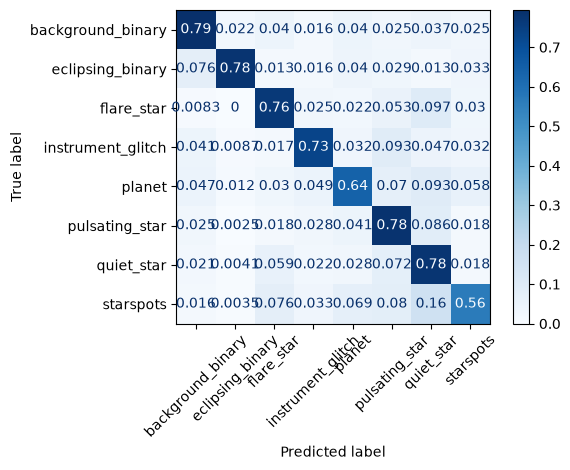

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

y_pred = model.predict(X_va)

print(classification_report(
    y_va,
    y_pred,
    digits=4,
    zero_division=0,
))

print("Macro-F1:", f1_score(
    y_va,
    y_pred,
    average="macro",
))

ConfusionMatrixDisplay.from_predictions(
    y_va,
    y_pred,
    normalize="true",
    xticks_rotation=45,
    cmap="Blues",
)

plt.tight_layout()
plt.show()

## Train on everything and write the submission

In [5]:
model.fit(X, train.label)
sub = pd.DataFrame({'id': test.id, 'label': model.predict(X_test)})
sub.to_csv('submission.csv', index=False)
sub.label.value_counts()

label
instrument_glitch    1895
pulsating_star       1351
flare_star           1005
quiet_star            637
background_binary     565
starspots             547
eclipsing_binary      538
planet                462
Name: count, dtype: int64

## Ideas to climb the leaderboard
- **Detrend**: subtract the median curve of all stars on the same `camera`/`ccd`, then remove slow variations with a median filter.
- **Search for transits**: run a Box Least Squares search (`astropy.timeseries.BoxLeastSquares`) and fold on the best period.
- **Vet the dip**: depth, duration, U vs V shape, odd vs even depth, a secondary eclipse at phase 0.5, and **the centroid shift during the dip**.
- **Ignore or use the flags**: momentum dumps (`quality & 1`) cause blips that are not transits.
- **Frequencies**: a periodogram tells spots (days) from pulsations (hours).
- **Flares**: bright outliers with a decaying tail vs single-point cosmic rays.
- **Deep learning**: a 1D CNN on detrended flux + folded flux + centroids.

In [18]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        f"Could not find src directory at {PROJECT_ROOT / 'src'}. "
        "Check your notebook's working directory."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from src.features.centroid import extract_centroid_features

In [22]:
from src.features.centroid import extract_centroid_features

X_centroid = extract_centroid_features(train_cen)
X_centroid_test = extract_centroid_features(test_cen)

print("Train:", X_centroid.shape)
print("Test:", X_centroid_test.shape)

print("\nMissing values:")
print(X_centroid.isna().sum())

print("\nFeature summary:")
print(X_centroid.describe().round(4))

Train: (18000, 8)
Test: (7000, 8)

Missing values:
centroid_x_std            0
centroid_x_mad            0
centroid_x_diff_median    0
centroid_x_dev_p95        0
centroid_y_std            0
centroid_y_mad            0
centroid_y_diff_median    0
centroid_y_dev_p95        0
dtype: int64

Feature summary:
       centroid_x_std  centroid_x_mad  centroid_x_diff_median  \
count      18000.0000      18000.0000              18000.0000   
mean           4.2252          2.9183                  2.4792   
std            2.1467          1.2701                  1.8484   
min            1.0400          0.6086                  0.2134   
25%            2.7244          1.9360                  0.9386   
50%            3.8446          2.7124                  1.9478   
75%            5.3906          3.7021                  3.6658   
max           62.5535         15.9277                  9.0444   

       centroid_x_dev_p95  centroid_y_std  centroid_y_mad  \
count          18000.0000      18000.0000      

In [23]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

# Assemble features
X_base = X.reset_index(drop=True).copy()
X_temp = X_temporal.reset_index(drop=True).copy()
X_cent = X_centroid.reset_index(drop=True).copy()

X_all = pd.concat([X_base, X_temp], axis=1)
X_with_centroid = pd.concat([X_all, X_cent], axis=1)

top3_temporal = [
    "trend_slope",
    "diff_abs_median",
    "diff_std",
]

feature_sets = {
    "baseline": list(X_base.columns),
    "top_3": list(X_base.columns) + top3_temporal,
    "all_temporal": list(X_all.columns),
    "top_3_plus_centroid": (
        list(X_base.columns) + top3_temporal + list(X_cent.columns)
    ),
    "all_temporal_plus_centroid": list(X_with_centroid.columns),
}

model_template = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.06,
    class_weight="balanced",
    random_state=0,
)

seeds = [21, 42, 123, 2026, 7]
results = []

for seed in seeds:
    train_idx, val_idx = train_test_split(
        np.arange(len(train)),
        test_size=0.2,
        stratify=train["label"],
        random_state=seed,
    )

    y_train = train["label"].iloc[train_idx]
    y_val = train["label"].iloc[val_idx]

    for experiment, columns in feature_sets.items():
        features = (
            X_with_centroid
            if "centroid" in experiment
            else X_all
        )

        model = clone(model_template)
        model.fit(features.iloc[train_idx][columns], y_train)

        predictions = model.predict(
            features.iloc[val_idx][columns]
        )

        results.append({
            "seed": seed,
            "experiment": experiment,
            "macro_f1": f1_score(
                y_val, predictions, average="macro"
            ),
        })

results_df = pd.DataFrame(results)

print("Individual split scores:")
print(
    results_df.pivot(
        index="seed",
        columns="experiment",
        values="macro_f1",
    ).round(4)
)

print("\nSummary:")
print(
    results_df.groupby("experiment")["macro_f1"]
    ["macro_f1"] if False else
    results_df.groupby("experiment")["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Individual split scores:
experiment  all_temporal  all_temporal_plus_centroid  baseline   top_3  \
seed                                                                     
7                 0.4731                      0.4757    0.4253  0.4648   
21                0.4871                      0.4834    0.4307  0.4777   
42                0.4722                      0.4790    0.4307  0.4813   
123               0.4767                      0.4750    0.4207  0.4680   
2026              0.4560                      0.4610    0.4161  0.4608   

experiment  top_3_plus_centroid  
seed                             
7                        0.4724  
21                       0.4836  
42                       0.4694  
123                      0.4741  
2026                     0.4674  

Summary:
                              mean     std     min     max
experiment                                                
all_temporal                0.4730  0.0112  0.4560  0.4871
all_temporal_plus_centroid  0.4

Macro-F1: 0.4694

Classification report:
                   precision    recall  f1-score   support

background_binary       0.41      0.43      0.42       321
 eclipsing_binary       0.77      0.55      0.64       449
       flare_star       0.40      0.47      0.43       361
instrument_glitch       0.60      0.52      0.56       344
           planet       0.29      0.28      0.29       429
   pulsating_star       0.53      0.61      0.56       395
       quiet_star       0.48      0.60      0.53       725
        starspots       0.36      0.29      0.32       576

         accuracy                           0.47      3600
        macro avg       0.48      0.47      0.47      3600
     weighted avg       0.48      0.47      0.47      3600



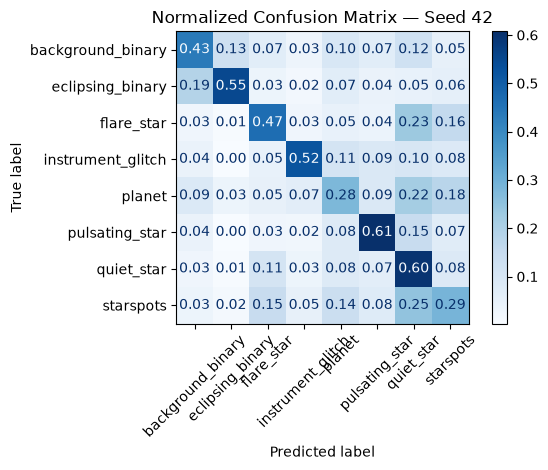

In [24]:

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)
import matplotlib.pyplot as plt

# Reuse the same validation split as seed 42
# and the same feature set: top 3 temporal + centroid.

top3_temporal = [
    "trend_slope",
    "diff_abs_median",
    "diff_std",
]

X_selected = pd.concat(
    [X_base, X_temp, X_cent],
    axis=1,
)

selected_columns = (
    list(X_base.columns)
    + top3_temporal
    + list(X_cent.columns)
)

# Reuse the model configuration from the previous experiment.
model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.06,
    class_weight="balanced",
    random_state=0,
)

model.fit(
    X_selected.iloc[X_tr][selected_columns],
    y_tr,
)

predictions = model.predict(
    X_selected.iloc[X_va][selected_columns]
)

print("Macro-F1:", round(
    f1_score(y_va, predictions, average="macro"), 4
))

print("\nClassification report:")
print(classification_report(
    y_va,
    predictions,
    labels=sorted(train["label"].unique()),
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_va,
    predictions,
    labels=sorted(train["label"].unique()),
    xticks_rotation=45,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
)

plt.title("Normalized Confusion Matrix — Seed 42")
plt.tight_layout()
plt.show()


In [25]:
from src.features.periodic import extract_periodic_features

X_periodic = extract_periodic_features(train_flux)
X_periodic_test = extract_periodic_features(test_flux)

print(X_periodic.shape)
print(X_periodic.isna().sum())

(18000, 5)
autocorr_lag_5      0
autocorr_lag_10     0
autocorr_lag_20     0
autocorr_lag_50     0
autocorr_lag_100    0
dtype: int64


In [26]:

# Existing candidate: top 3 temporal + centroid
# New candidate: existing candidate + 5 autocorrelation features

X_periodic = X_periodic.reset_index(drop=True)

X_candidate = pd.concat(
    [
        X_base.reset_index(drop=True),
        X_temp[top3_temporal].reset_index(drop=True),
        X_cent.reset_index(drop=True),
    ],
    axis=1,
)

X_candidate_periodic = pd.concat(
    [
        X_candidate,
        X_periodic,
    ],
    axis=1,
)

feature_sets = {
    "top3_plus_centroid": list(X_candidate.columns),
    "top3_centroid_periodic": list(X_candidate_periodic.columns),
}

results_periodic = []

for seed in [21, 42, 123, 2026, 7]:
    train_idx, val_idx = train_test_split(
        np.arange(len(train)),
        test_size=0.2,
        stratify=train["label"],
        random_state=seed,
    )

    y_train = train["label"].iloc[train_idx]
    y_val = train["label"].iloc[val_idx]

    for experiment, columns in feature_sets.items():
        features = (
            X_candidate_periodic
            if experiment == "top3_centroid_periodic"
            else X_candidate
        )

        model = clone(model_template)
        model.fit(features.iloc[train_idx][columns], y_train)

        predictions = model.predict(
            features.iloc[val_idx][columns]
        )

        results_periodic.append({
            "seed": seed,
            "experiment": experiment,
            "macro_f1": f1_score(
                y_val, predictions, average="macro"
            ),
        })

periodic_results_df = pd.DataFrame(results_periodic)

print("Individual split scores:")
print(
    periodic_results_df.pivot(
        index="seed",
        columns="experiment",
        values="macro_f1",
    ).round(4)
)

print("\nSummary:")
print(
    periodic_results_df.groupby("experiment")["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Individual split scores:
experiment  top3_centroid_periodic  top3_plus_centroid
seed                                                  
7                           0.4765              0.4724
21                          0.4810              0.4836
42                          0.4911              0.4694
123                         0.4792              0.4741
2026                        0.4754              0.4674

Summary:
                          mean     std     min     max
experiment                                            
top3_centroid_periodic  0.4806  0.0063  0.4754  0.4911
top3_plus_centroid      0.4734  0.0063  0.4674  0.4836


Macro-F1: 0.4911

Classification report:
                   precision    recall  f1-score   support

background_binary       0.43      0.46      0.44       321
 eclipsing_binary       0.76      0.56      0.65       449
       flare_star       0.48      0.49      0.49       361
instrument_glitch       0.63      0.58      0.60       344
           planet       0.30      0.28      0.29       429
   pulsating_star       0.56      0.63      0.59       395
       quiet_star       0.46      0.61      0.53       725
        starspots       0.39      0.30      0.34       576

         accuracy                           0.49      3600
        macro avg       0.50      0.49      0.49      3600
     weighted avg       0.49      0.49      0.49      3600



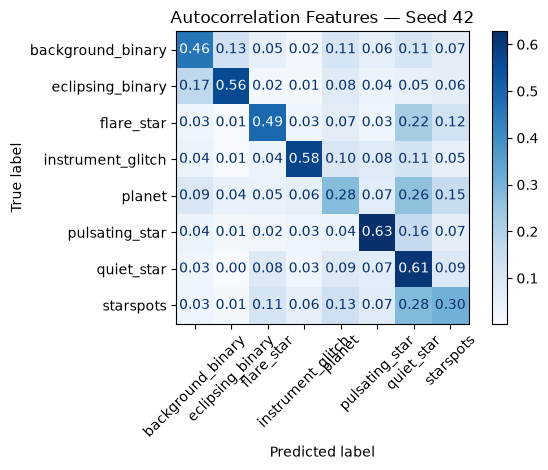

In [27]:

# Evaluate the new candidate on the existing seed-42 split.

model = clone(model_template)

model.fit(
    X_candidate_periodic.iloc[X_tr],
    y_tr,
)

predictions_periodic = model.predict(
    X_candidate_periodic.iloc[X_va]
)

print(
    "Macro-F1:",
    round(
        f1_score(y_va, predictions_periodic, average="macro"),
        4,
    ),
)

print("\nClassification report:")
print(
    classification_report(
        y_va,
        predictions_periodic,
        labels=sorted(train["label"].unique()),
        zero_division=0,
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_va,
    predictions_periodic,
    labels=sorted(train["label"].unique()),
    xticks_rotation=45,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
)

plt.title("Autocorrelation Features — Seed 42")
plt.tight_layout()
plt.show()


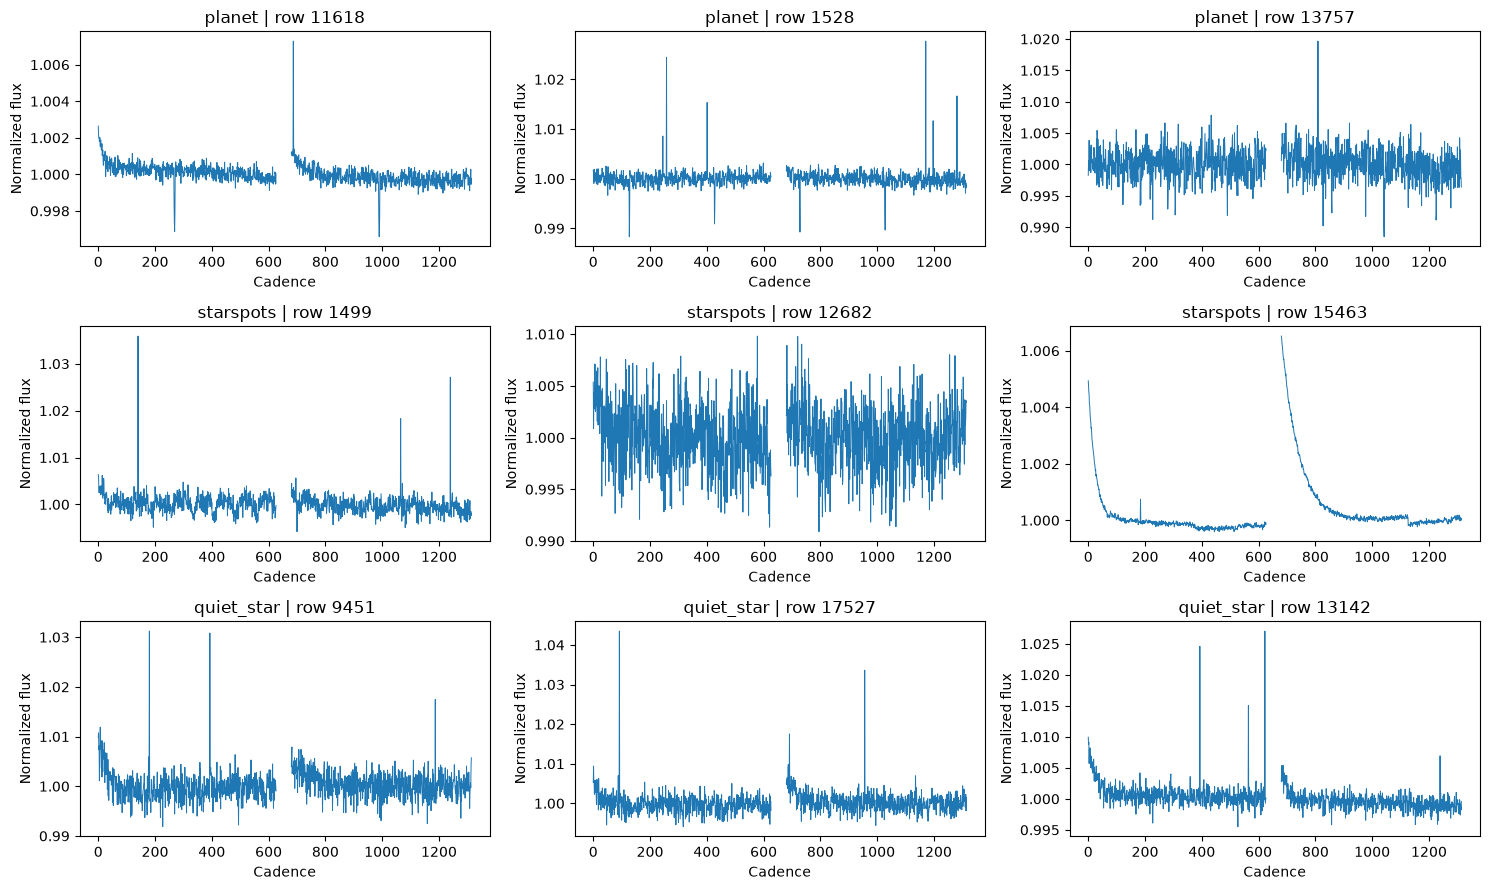

In [28]:

rng = np.random.default_rng(42)
classes_to_inspect = ["planet", "starspots", "quiet_star"]

fig, axes = plt.subplots(
    len(classes_to_inspect), 3,
    figsize=(15, 9),
)

for row, label in enumerate(classes_to_inspect):
    indices = np.flatnonzero(
        train["label"].to_numpy() == label
    )
    chosen = rng.choice(
        indices, size=3, replace=False
    )

    for col, idx in enumerate(chosen):
        flux = train_flux[idx].astype(float)
        median = np.nanmedian(flux)

        if np.isfinite(median) and abs(median) > 1e-8:
            flux = flux / median

        axes[row, col].plot(flux, linewidth=0.7)
        axes[row, col].set_title(
            f"{label} | row {idx}"
        )
        axes[row, col].set_xlabel("Cadence")
        axes[row, col].set_ylabel("Normalized flux")

plt.tight_layout()
plt.show()


In [29]:
from src.features.artifacts import extract_artifact_features

X_artifacts = extract_artifact_features(train_flux)
X_artifacts_test = extract_artifact_features(test_flux)

print(X_artifacts.shape)
print(X_artifacts.isna().sum())
print(X_artifacts.describe().round(5))

(18000, 3)
extreme_outlier_fraction    0
max_consecutive_jump        0
large_jump_fraction         0
dtype: int64
       extreme_outlier_fraction  max_consecutive_jump  large_jump_fraction
count               18000.00000           18000.00000          18000.00000
mean                    0.01338              70.96564              0.01007
std                     0.02953             458.83084              0.02633
min                     0.00000               1.53680              0.00000
25%                     0.00079              12.22005              0.00152
50%                     0.00158              21.29858              0.00304
75%                     0.00792              41.86890              0.00533
max                     0.38510           22951.71875              0.31431


In [30]:

# Existing candidate: top 3 temporal + centroid + autocorrelation
# New candidate: existing candidate + 3 artifact features

X_artifacts = X_artifacts.reset_index(drop=True)

X_candidate_artifacts = pd.concat(
    [
        X_candidate_periodic.reset_index(drop=True),
        X_artifacts,
    ],
    axis=1,
)

artifact_results = []

for seed in [21, 42, 123, 2026, 7]:
    train_idx, val_idx = train_test_split(
        np.arange(len(train)),
        test_size=0.2,
        stratify=train["label"],
        random_state=seed,
    )

    y_train = train["label"].iloc[train_idx]
    y_val = train["label"].iloc[val_idx]

    for name, features in [
        ("current_33", X_candidate_periodic),
        ("plus_artifact_36", X_candidate_artifacts),
    ]:
        model = clone(model_template)

        model.fit(features.iloc[train_idx], y_train)
        predictions = model.predict(features.iloc[val_idx])

        artifact_results.append({
            "seed": seed,
            "experiment": name,
            "macro_f1": f1_score(
                y_val, predictions, average="macro"
            ),
        })

artifact_results_df = pd.DataFrame(artifact_results)

print("Individual split scores:")
print(
    artifact_results_df.pivot(
        index="seed",
        columns="experiment",
        values="macro_f1",
    ).round(4)
)

print("\nSummary:")
print(
    artifact_results_df.groupby("experiment")["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Individual split scores:
experiment  current_33  plus_artifact_36
seed                                    
7               0.4765            0.4898
21              0.4810            0.4987
42              0.4911            0.4993
123             0.4792            0.4889
2026            0.4754            0.4967

Summary:
                    mean     std     min     max
experiment                                      
current_33        0.4806  0.0063  0.4754  0.4911
plus_artifact_36  0.4947  0.0050  0.4889  0.4993


Macro-F1: 0.4993

Classification report:
                   precision    recall  f1-score   support

background_binary       0.42      0.44      0.43       321
 eclipsing_binary       0.76      0.58      0.66       449
       flare_star       0.52      0.51      0.51       361
instrument_glitch       0.62      0.58      0.60       344
           planet       0.33      0.31      0.32       429
   pulsating_star       0.54      0.63      0.58       395
       quiet_star       0.47      0.62      0.54       725
        starspots       0.41      0.31      0.35       576

         accuracy                           0.50      3600
        macro avg       0.51      0.50      0.50      3600
     weighted avg       0.50      0.50      0.50      3600



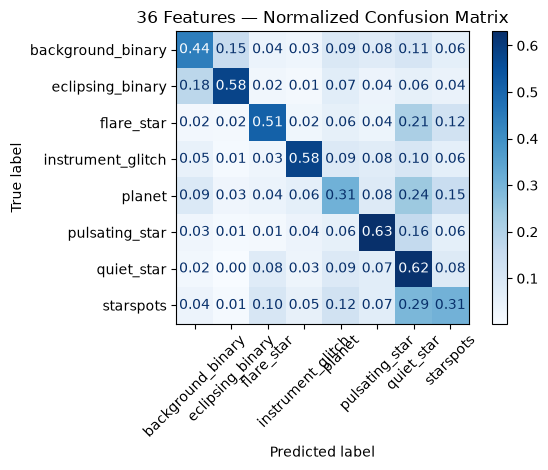

In [31]:

# Reuse X_tr, X_va, y_tr, y_va from seed 42.

model = clone(model_template)

model.fit(
    X_candidate_artifacts.iloc[X_tr],
    y_tr,
)

predictions_artifacts = model.predict(
    X_candidate_artifacts.iloc[X_va]
)

print(
    "Macro-F1:",
    round(
        f1_score(
            y_va, predictions_artifacts, average="macro"
        ),
        4,
    ),
)

print("\nClassification report:")
print(
    classification_report(
        y_va,
        predictions_artifacts,
        labels=sorted(train["label"].unique()),
        zero_division=0,
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_va,
    predictions_artifacts,
    labels=sorted(train["label"].unique()),
    xticks_rotation=45,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
)

plt.title("36 Features — Normalized Confusion Matrix")
plt.tight_layout()
plt.show()


In [33]:

# Inspect missingness and cadence quality.
# Reuse train_flux and train_cadences from the loaded dataset.

flux_missing = np.isnan(train_flux).mean(axis=1)

print("Flux missing fraction:")
print(pd.Series(flux_missing).describe().round(5))

print("\nRows with any missing flux:")
print(int((np.isnan(train_flux).any(axis=1)).sum()))

print("\nCadence metadata columns:")
print(cad.columns.tolist())

print("\nCadence quality distribution:")
print(cad["quality"].value_counts(dropna=False).sort_index())

missingness_by_class = pd.DataFrame({
    "label": train["label"].to_numpy(),
    "missing_fraction": flux_missing,
})

print(
    missingness_by_class.groupby("label")["missing_fraction"]
    .agg(["mean", "median", "max"])
    .round(5)
)


Flux missing fraction:
count    18000.0000
mean         0.0403
std          0.0000
min          0.0403
25%          0.0403
50%          0.0403
75%          0.0403
max          0.0403
dtype: float64

Rows with any missing flux:
18000

Cadence metadata columns:
['cadence', 'time_btjd', 'quality']

Cadence quality distribution:
quality
0    1221
1       8
2      33
4      53
Name: count, dtype: int64
                     mean  median     max
label                                    
background_binary  0.0403  0.0403  0.0403
eclipsing_binary   0.0403  0.0403  0.0403
flare_star         0.0403  0.0403  0.0403
instrument_glitch  0.0403  0.0403  0.0403
planet             0.0403  0.0403  0.0403
pulsating_star     0.0403  0.0403  0.0403
quiet_star         0.0403  0.0403  0.0403
starspots          0.0403  0.0403  0.0403


In [34]:
# Check whether missing flux occurs at the same cadence positions
missing_mask = np.isnan(train_flux)

missing_per_cadence = missing_mask.sum(axis=0)

print("Minimum stars missing at a cadence:", missing_per_cadence.min())
print("Maximum stars missing at a cadence:", missing_per_cadence.max())
print("Cadences missing for every star:",
      np.sum(missing_per_cadence == len(train_flux)))
print("Cadences with no missing values:",
      np.sum(missing_per_cadence == 0))

print("\nFirst 30 cadence missing counts:")
print(missing_per_cadence[:30])

Minimum stars missing at a cadence: 0
Maximum stars missing at a cadence: 18000
Cadences missing for every star: 53
Cadences with no missing values: 1262

First 30 cadence missing counts:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [35]:
print("Flux cadences:", train_flux.shape[1])
print("Cadence metadata rows:", len(cad))

print(cad.head())
print(cad["quality"].value_counts().sort_index())

Flux cadences: 1315
Cadence metadata rows: 1315
   cadence    time_btjd  quality
0        0  2104.272000        2
1        1  2104.292833        2
2        2  2104.313667        2
3        3  2104.334500        2
4        4  2104.355333        2
quality
0    1221
1       8
2      33
4      53
Name: count, dtype: int64


In [36]:
quality_mask = (
    cad["quality"].to_numpy() == 0
)

print("Total cadences:", len(quality_mask))
print("Quality-zero cadences:", quality_mask.sum())
print("Excluded cadences:", (~quality_mask).sum())

Total cadences: 1315
Quality-zero cadences: 1221
Excluded cadences: 94


In [37]:
train_flux_quality = train_flux[:, quality_mask]
test_flux_quality = test_flux[:, quality_mask]

train_centroid_quality = train_cen[:, :, quality_mask]
test_centroid_quality = test_cen[:, :, quality_mask]

print("Filtered train flux:", train_flux_quality.shape)
print("Filtered test flux:", test_flux_quality.shape)

Filtered train flux: (18000, 1221)
Filtered test flux: (7000, 1221)


In [39]:

# Recompute all four feature groups from quality-filtered data.

X_base_q = simple_features(
    train_flux_quality,
    train,
)

X_temp_q = temporal_features(train_flux_quality)

X_cent_q = extract_centroid_features(
    train_centroid_quality
)

X_periodic_q = extract_periodic_features(
    train_flux_quality
)

X_artifacts_q = extract_artifact_features(
    train_flux_quality
)

print("Shapes:")
print("Base:", X_base_q.shape)
print("Temporal:", X_temp_q.shape)
print("Centroid:", X_cent_q.shape)
print("Periodic:", X_periodic_q.shape)
print("Artifacts:", X_artifacts_q.shape)

print("\nTotal missing feature values:")
print(
    pd.concat(
        [
            X_base_q.reset_index(drop=True),
            X_temp_q.reset_index(drop=True),
            X_cent_q.reset_index(drop=True),
            X_periodic_q.reset_index(drop=True),
            X_artifacts_q.reset_index(drop=True),
        ],
        axis=1,
    ).isna().sum().sum()
)


Shapes:
Base: (18000, 17)
Temporal: (18000, 6)
Centroid: (18000, 8)
Periodic: (18000, 5)
Artifacts: (18000, 3)

Total missing feature values:
0


In [40]:

X_quality_candidate = pd.concat(
    [
        X_base_q.reset_index(drop=True),
        X_temp_q[top3_temporal].reset_index(drop=True),
        X_cent_q.reset_index(drop=True),
        X_periodic_q.reset_index(drop=True),
        X_artifacts_q.reset_index(drop=True),
    ],
    axis=1,
)

print("Original shape:", X_candidate_artifacts.shape)
print("Filtered shape:", X_quality_candidate.shape)

quality_results = []

for seed in [7, 21, 42, 123, 2026]:
    train_idx, val_idx = train_test_split(
        np.arange(len(train)),
        test_size=0.2,
        stratify=train["label"],
        random_state=seed,
    )

    y_train = train["label"].iloc[train_idx]
    y_val = train["label"].iloc[val_idx]

    for name, features in [
        ("original_36", X_candidate_artifacts),
        ("quality_filtered_36", X_quality_candidate),
    ]:
        model = clone(model_template)
        model.fit(features.iloc[train_idx], y_train)

        predictions = model.predict(features.iloc[val_idx])

        quality_results.append({
            "seed": seed,
            "experiment": name,
            "macro_f1": f1_score(
                y_val, predictions, average="macro"
            ),
        })

quality_results_df = pd.DataFrame(quality_results)

print("\nIndividual split scores:")
print(
    quality_results_df.pivot(
        index="seed",
        columns="experiment",
        values="macro_f1",
    ).round(4)
)

print("\nSummary:")
print(
    quality_results_df.groupby("experiment")["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Original shape: (18000, 36)
Filtered shape: (18000, 36)

Individual split scores:
experiment  original_36  quality_filtered_36
seed                                        
7                0.4898               0.5048
21               0.4987               0.5135
42               0.4993               0.5116
123              0.4889               0.5159
2026             0.4967               0.4998

Summary:
                       mean     std     min     max
experiment                                         
original_36          0.4947  0.0050  0.4889  0.4993
quality_filtered_36  0.5091  0.0067  0.4998  0.5159


In [41]:

# Seed 42: compare original and quality-filtered pipelines.

model_original = clone(model_template)
model_filtered = clone(model_template)

model_original.fit(
    X_candidate_artifacts.iloc[X_tr],
    y_tr,
)

model_filtered.fit(
    X_quality_candidate.iloc[X_tr],
    y_tr,
)

pred_original = model_original.predict(
    X_candidate_artifacts.iloc[X_va]
)

pred_filtered = model_filtered.predict(
    X_quality_candidate.iloc[X_va]
)

labels = sorted(train["label"].unique())

report_original = classification_report(
    y_va,
    pred_original,
    labels=labels,
    output_dict=True,
    zero_division=0,
)

report_filtered = classification_report(
    y_va,
    pred_filtered,
    labels=labels,
    output_dict=True,
    zero_division=0,
)

class_comparison = pd.DataFrame({
    "original_f1": {
        label: report_original[label]["f1-score"]
        for label in labels
    },
    "filtered_f1": {
        label: report_filtered[label]["f1-score"]
        for label in labels
    },
})

class_comparison["change"] = (
    class_comparison["filtered_f1"]
    - class_comparison["original_f1"]
)

print(class_comparison.round(4).to_string())

print("\nOriginal macro-F1:",
      round(f1_score(y_va, pred_original, average="macro"), 4))

print("Filtered macro-F1:",
      round(f1_score(y_va, pred_filtered, average="macro"), 4))


                   original_f1  filtered_f1  change
background_binary       0.4312       0.4584  0.0272
eclipsing_binary        0.6557       0.6658  0.0101
flare_star              0.5139       0.5175  0.0037
instrument_glitch       0.6015       0.6133  0.0118
planet                  0.3185       0.3272  0.0088
pulsating_star          0.5845       0.5899  0.0054
quiet_star              0.5377       0.5588  0.0212
starspots               0.3513       0.3621  0.0108

Original macro-F1: 0.4993
Filtered macro-F1: 0.5116


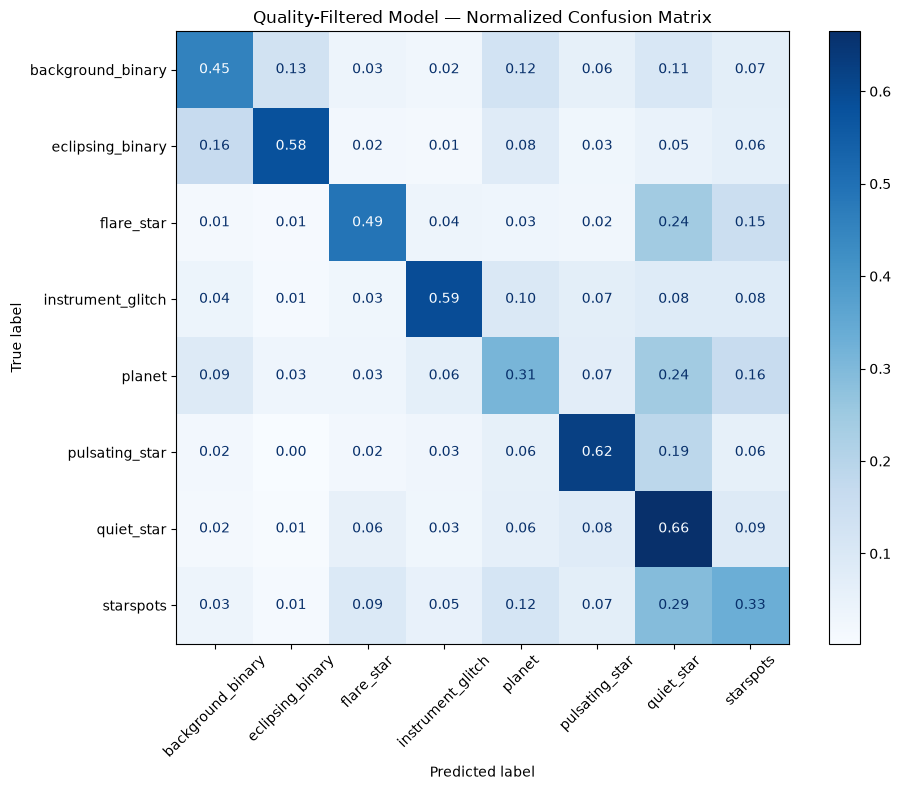

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


labels = sorted(train["label"].unique())

cm = confusion_matrix(
    y_va,
    pred_filtered,
    labels=labels,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f"
)

ax.set_title("Quality-Filtered Model — Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

In [46]:
import importlib
import src.features.dip as dip_module

importlib.reload(dip_module)

X_dip = dip_module.dip_features(train_flux_quality)
X_test_dip = dip_module.dip_features(test_flux_quality)

print(X_dip["deepest_dip"].describe().round(4))
print("Negative values:", (X_dip["deepest_dip"] < 0).sum())
print("NaNs:", X_dip.isna().sum().sum())
print("Infinite values:", np.isinf(X_dip.to_numpy()).sum())

count    18000.0000
mean         6.3876
std         24.8792
min          0.7012
25%          2.6995
50%          3.1728
75%          3.9855
max        860.3981
Name: deepest_dip, dtype: float64
Negative values: 0
NaNs: 0
Infinite values: 0


In [47]:
# Append the four new features to the existing filtered 36-feature matrix.
X_quality_dip = pd.concat(
    [
        X_quality_candidate.reset_index(drop=True),
        X_dip.reset_index(drop=True),
    ],
    axis=1,
)

assert X_quality_dip.shape == (18000, 40)
assert X_quality_dip.columns.is_unique

print("Candidate shape:", X_quality_dip.shape)

Candidate shape: (18000, 40)


In [48]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

y = train["label"].reset_index(drop=True)
seeds = [7, 21, 42, 123, 2026]

results_dip = []

for seed in seeds:
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_quality_dip,
        y,
        test_size=0.2,
        random_state=seed,
        stratify=y,
    )

    model = clone(model_template)
    model.fit(X_tr, y_tr)
    pred = model.predict(X_va)

    score = f1_score(y_va, pred, average="macro")
    results_dip.append({"seed": seed, "macro_f1": score})

    print(f"Seed {seed}: {score:.4f}")

scores = [row["macro_f1"] for row in results_dip]

print(f"\nMean macro-F1: {np.mean(scores):.4f}")
print(f"Std deviation: {np.std(scores):.4f}")

Seed 7: 0.5132
Seed 21: 0.5240
Seed 42: 0.5263
Seed 123: 0.5224
Seed 2026: 0.5156

Mean macro-F1: 0.5203
Std deviation: 0.0050


In [49]:


y = train["label"].reset_index(drop=True)

X_tr, X_va, y_tr, y_va = train_test_split(
    X_quality_dip,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

model_dip = clone(model_template)
model_dip.fit(X_tr, y_tr)
pred_dip = model_dip.predict(X_va)

report = classification_report(
    y_va,
    pred_dip,
    output_dict=True,
    zero_division=0,
)

class_f1 = pd.DataFrame({
    "f1": {
        label: report[label]["f1-score"]
        for label in sorted(y.unique())
    },
    "precision": {
        label: report[label]["precision"]
        for label in sorted(y.unique())
    },
    "recall": {
        label: report[label]["recall"]
        for label in sorted(y.unique())
    },
})

display(class_f1.round(4))

,f1,precision,recall
background_binary,0.4700,0.4636,0.4766
eclipsing_binary,0.6684,0.8121,0.5679
flare_star,0.5150,0.5325,0.4986
instrument_glitch,0.6193,0.6447,0.5959
planet,0.3840,0.4010,0.3683
pulsating_star,0.5986,0.5638,0.6380
quiet_star,0.5525,0.4869,0.6386
starspots,0.4022,0.4291,0.3785


In [50]:
# Verify that train and test feature matrices have identical schemas.
assert X_quality_dip.shape == (18000, 40)
assert X_test_dip.shape == (7000, 4)

print("Training features:", X_quality_dip.shape)
print("Dip test features:", X_test_dip.shape)
print("Train columns unique:", X_quality_dip.columns.is_unique)
print("Train NaNs:", X_quality_dip.isna().sum().sum())
print("Test dip NaNs:", X_test_dip.isna().sum().sum())

Training features: (18000, 40)
Dip test features: (7000, 4)
Train columns unique: True
Train NaNs: 0
Test dip NaNs: 0


In [51]:
# Inspect existing feature matrices and their shapes.
for name in [
    "X_test_quality",
    "X_test_quality_base",
    "X_test_quality_temporal",
    "X_test_quality_centroid",
    "X_test_quality_periodic",
    "X_test_quality_artifacts",
    "X_test_dip",
]:
    if name in globals():
        value = globals()[name]
        print(name, value.shape)

X_test_dip (7000, 4)


In [52]:
print("Training feature columns:")
print(X_quality_candidate.columns.tolist())

print("\nAvailable feature-related variables:")
for name, value in list(globals().items()):
    if name.startswith(("X_", "test_", "train_")):
        if hasattr(value, "shape"):
            print(f"{name}: {value.shape}")

Training feature columns:
['std', 'mad', 'min', 'max', 'skew', 'kurt', 'p1', 'p5', 'p25', 'p75', 'p95', 'p99', 'tmag', 'teff', 'logg', 'radius', 'contamination', 'trend_slope', 'diff_abs_median', 'diff_std', 'centroid_x_std', 'centroid_x_mad', 'centroid_x_diff_median', 'centroid_x_dev_p95', 'centroid_y_std', 'centroid_y_mad', 'centroid_y_diff_median', 'centroid_y_dev_p95', 'autocorr_lag_5', 'autocorr_lag_10', 'autocorr_lag_20', 'autocorr_lag_50', 'autocorr_lag_100', 'extreme_outlier_fraction', 'max_consecutive_jump', 'large_jump_fraction']

Available feature-related variables:
train_flux: (18000, 1315)
train_cen: (18000, 2, 1315)
test_flux: (7000, 1315)
X_test: (7000, 17)
X_tr: (14400, 40)
X_va: (3600, 40)
X_temporal: (18000, 6)
X_test_temporal: (7000, 6)
X_v2: (18000, 23)
X_test_v2: (7000, 23)
X_base_tr: (14400, 17)
X_base_va: (3600, 17)
X_new_tr: (14400, 23)
X_new_va: (3600, 23)
X_tr_frame: (14400, 17)
X_va_frame: (3600, 17)
X_all: (18000, 23)
X_train_exp: (14400, 18)
X_valid_exp: (3

In [58]:
X_base_test_q = simple_features(test_flux_quality, test)
X_temp_test_q = temporal_features(test_flux_quality)
X_cent_test_q = extract_centroid_features(test_centroid_quality)
X_periodic_test_q = extract_periodic_features(test_flux_quality)
X_artifacts_test_q = extract_artifact_features(test_flux_quality)

selected_temporal = [
    "trend_slope",
    "diff_abs_median",
    "diff_std",
]

X_test_quality_candidate = pd.concat([
    X_base_test_q.reset_index(drop=True),
    X_temp_test_q[selected_temporal].reset_index(drop=True),
    X_cent_test_q.reset_index(drop=True),
    X_periodic_test_q.reset_index(drop=True),
    X_artifacts_test_q.reset_index(drop=True),
], axis=1)

X_test_quality_dip = pd.concat([
    X_test_quality_candidate.reset_index(drop=True),
    X_test_dip.reset_index(drop=True),
], axis=1)

# Enforce the exact training column order.
X_test_quality_dip = X_test_quality_dip[X_quality_dip.columns]

# Validate before training.
assert X_test_quality_dip.shape == (7000, 40)
assert X_test_quality_dip.columns.equals(X_quality_dip.columns)
assert X_test_quality_dip.columns.is_unique
assert np.isfinite(X_test_quality_dip.to_numpy()).all()

print("Test shape:", X_test_quality_dip.shape)
print("Column order matches:", X_test_quality_dip.columns.equals(X_quality_dip.columns))
print("All values finite:", np.isfinite(X_test_quality_dip.to_numpy()).all())

Test shape: (7000, 40)
Column order matches: True
All values finite: True


In [59]:


X_final = X_quality_dip
X_test_final = X_test_quality_dip
y = train["label"]

# Start from the same model configuration used during validation.
model_final = clone(model_template)

model_final.fit(X_final, y)

print("Final model trained.")
print("Training rows:", len(X_final))
print("Training features:", X_final.shape[1])
print("Classes learned:", model_final.classes_)

Final model trained.
Training rows: 18000
Training features: 40
Classes learned: ['background_binary' 'eclipsing_binary' 'flare_star' 'instrument_glitch'
 'planet' 'pulsating_star' 'quiet_star' 'starspots']


In [60]:
pred_test = model_final.predict(X_test_final)

print("Predictions generated:", len(pred_test))
print("Predicted class distribution:")
print(pd.Series(pred_test).value_counts())

Predictions generated: 7000
Predicted class distribution:
instrument_glitch    2430
starspots             864
pulsating_star        836
flare_star            697
planet                693
eclipsing_binary      577
background_binary     469
quiet_star            434
Name: count, dtype: int64


In [61]:
submission = pd.DataFrame({
    "id": test["id"].to_numpy(),
    "label": pred_test
})

# Validate the required submission format.
assert submission.columns.tolist() == ["id", "label"]
assert len(submission) == 7000
assert submission["id"].notna().all()
assert submission["label"].notna().all()
assert submission["id"].is_unique
assert set(submission["label"].unique()).issubset(set(train["label"].unique()))

submission.to_csv("submission.csv", index=False)

# Read it back to verify the actual saved file.
check = pd.read_csv("submission.csv")

assert check.shape == (7000, 2)
assert check.columns.tolist() == ["id", "label"]

print("Submission saved and validated: submission.csv")
print(check.head())
print("Shape:", check.shape)

Submission saved and validated: submission.csv
             id              label
0  TIC914436805         quiet_star
1  TIC964940782  background_binary
2  TIC906185835         quiet_star
3  TIC927004741  instrument_glitch
4  TIC949385375  background_binary
Shape: (7000, 2)


In [62]:
comparison = pd.DataFrame({
    "train_count": train["label"].value_counts(),
    "test_predictions": pd.Series(pred_test).value_counts()
}).fillna(0).astype(int)

comparison["train_fraction"] = (
    comparison["train_count"] / len(train)
).round(3)

comparison["prediction_fraction"] = (
    comparison["test_predictions"] / len(pred_test)
).round(3)

print(comparison.sort_values("prediction_fraction", ascending=False))

                   train_count  test_predictions  train_fraction  \
instrument_glitch         1721              2430           0.096   
starspots                 2882               864           0.160   
pulsating_star            1973               836           0.110   
flare_star                1804               697           0.100   
planet                    2145               693           0.119   
eclipsing_binary          2247               577           0.125   
background_binary         1604               469           0.089   
quiet_star                3624               434           0.201   

                   prediction_fraction  
instrument_glitch                0.347  
starspots                        0.123  
pulsating_star                   0.119  
flare_star                       0.100  
planet                           0.099  
eclipsing_binary                 0.082  
background_binary                0.067  
quiet_star                       0.062  


In [63]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
import pandas as pd

y = train["label"]

X_tr, X_va, y_tr, y_va = train_test_split(
    X_quality_dip,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

diagnostic_model = clone(model_template)
diagnostic_model.fit(X_tr, y_tr)
val_pred = diagnostic_model.predict(X_va)

distribution_check = pd.DataFrame({
    "actual_count": y_va.value_counts(),
    "predicted_count": pd.Series(val_pred).value_counts()
}).fillna(0).astype(int)

distribution_check["actual_fraction"] = (
    distribution_check["actual_count"] / len(y_va)
).round(3)

distribution_check["predicted_fraction"] = (
    distribution_check["predicted_count"] / len(y_va)
).round(3)

print(distribution_check.sort_values(
    "predicted_fraction", ascending=False
))

                   actual_count  predicted_count  actual_fraction  \
quiet_star                  725              951            0.201   
starspots                   576              508            0.160   
pulsating_star              395              447            0.110   
planet                      429              394            0.119   
flare_star                  361              338            0.100   
background_binary           321              330            0.089   
instrument_glitch           344              318            0.096   
eclipsing_binary            449              314            0.125   

                   predicted_fraction  
quiet_star                      0.264  
starspots                       0.141  
pulsating_star                  0.124  
planet                          0.109  
flare_star                      0.094  
background_binary               0.092  
instrument_glitch               0.088  
eclipsing_binary                0.087  


In [64]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp

# Compare numerical features that we use in the model.
feature_cols = X_quality_dip.columns

rows = []

for col in feature_cols:
    train_values = X_quality_dip[col].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    test_values = X_test_quality_dip[col].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    result = ks_2samp(train_values, test_values)

    rows.append({
        "feature": col,
        "train_median": train_values.median(),
        "test_median": test_values.median(),
        "train_std": train_values.std(),
        "test_std": test_values.std(),
        "ks_statistic": result.statistic,
        "ks_pvalue": result.pvalue,
    })

shift_report = pd.DataFrame(rows).sort_values(
    "ks_statistic", ascending=False
)

print(shift_report.head(15).to_string(index=False))

         feature  train_median   test_median  train_std  test_std  ks_statistic     ks_pvalue
             p99  4.604180e-03  6.864715e-03   0.018911  0.016504      0.287183  0.000000e+00
             p95  2.778054e-03  3.718877e-03   0.017657  0.015435      0.225556 8.704410e-226
             p75  8.945213e-04  1.101454e-03   0.007976  0.006998      0.186794 1.997812e-154
   dip_asymmetry  9.213364e-01  8.221258e-01   5.437524  2.800430      0.184032 7.164570e-150
             mad  9.040240e-04  1.096791e-03   0.007935  0.006949      0.183714 2.367161e-149
             std  1.870689e-03  2.296682e-03   0.012497  0.011049      0.174079 4.877186e-134
             p25 -9.369807e-04 -1.097124e-03   0.007958  0.006968      0.165746 1.778742e-121
 autocorr_lag_50  1.230455e-01  2.174721e-01   0.265416  0.243560      0.154000 7.678790e-105
  autocorr_lag_5  3.873412e-01  5.606711e-01   0.338070  0.313549      0.136571  1.868442e-82
             max  1.344336e-02  1.551918e-02   0.027365  0.0

In [66]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

# Train = 0, test = 1.
X_domain = pd.concat(
    [
        X_quality_dip.reset_index(drop=True),
        X_test_quality_dip.reset_index(drop=True),
    ],
    ignore_index=True,
)

y_domain = np.concatenate([
    np.zeros(len(X_quality_dip), dtype=int),
    np.ones(len(X_test_quality_dip), dtype=int),
])

X_domain_train, X_domain_valid, y_domain_train, y_domain_valid = (
    train_test_split(
        X_domain,
        y_domain,
        test_size=0.25,
        random_state=42,
        stratify=y_domain,
    )
)

domain_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.06,
    max_leaf_nodes=15,
    random_state=42,
)

domain_model.fit(X_domain_train, y_domain_train)

domain_prob = domain_model.predict_proba(X_domain_valid)[:, 1]
domain_auc = roc_auc_score(y_domain_valid, domain_prob)

print(f"Train-vs-test domain ROC-AUC: {domain_auc:.4f}")

Train-vs-test domain ROC-AUC: 0.9402


In [67]:
import pandas as pd
import numpy as np

from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

domain_importance = permutation_importance(
    domain_model,
    X_domain_valid,
    y_domain_valid,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

domain_importance_df = pd.DataFrame({
    "feature": X_domain.columns,
    "importance_mean": domain_importance.importances_mean,
    "importance_std": domain_importance.importances_std,
}).sort_values("importance_mean", ascending=False)

print(domain_importance_df.head(15).to_string(index=False))

               feature  importance_mean  importance_std
       autocorr_lag_20         0.099433        0.003361
                   p99         0.069422        0.001970
           trend_slope         0.049871        0.002342
        centroid_y_mad         0.036176        0.001457
       autocorr_lag_50         0.032189        0.000817
        autocorr_lag_5         0.029897        0.001446
    centroid_y_dev_p95         0.020979        0.000485
        centroid_x_mad         0.019837        0.000801
           deepest_dip         0.016970        0.000658
    centroid_x_dev_p95         0.013711        0.000713
centroid_y_diff_median         0.004912        0.000388
      autocorr_lag_100         0.003455        0.000514
        centroid_x_std         0.003446        0.000367
                  tmag         0.003314        0.000169
     dip_concentration         0.003281        0.000599
